<a href="https://colab.research.google.com/github/sevaradevoloper/machine-learning-class-work/blob/main/cnndeeplearing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#cnn dars 1

In [ ]:
# rgb 255 max, 3d. oq qora 2d

In [2]:
import numpy as np
from sklearn.datasets import load_digits
digits = load_digits()

X,y = digits.images, digits.target

print(X.shape , X.min(), X.max() , y[555])
print(X[555].astype(int))
# (1797, 8, 8) soni,boyi ,eni

(1797, 8, 8) 0.0 16.0 9
[[ 0  0  2 10 14 10  0  0]
 [ 0  1 15  9  9 16  1  0]
 [ 0  7  9  0  9 12  0  0]
 [ 0  7  7  3 15 15  0  0]
 [ 0  2 15 15  7 16  1  0]
 [ 0  0  1  2  0  9  4  0]
 [ 0  0  5 13  4  8  9  0]
 [ 0  0  1 10 15 16  6  0]]


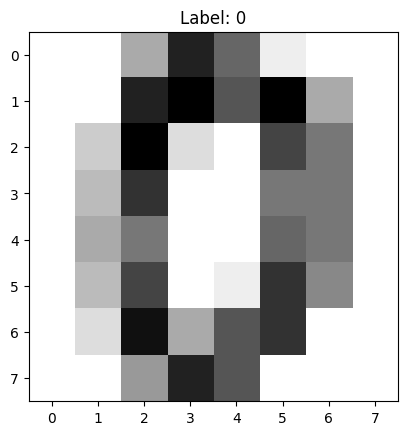

In [7]:
import matplotlib.pyplot as plt
plt.imshow(X[0], cmap="gray_r")
plt.title(f"Label: {y[0]}")
plt.show()

In [11]:
img = np.array([[3,3,0,0,0]]* 5)
k = np.array([[1,0,-1]]* 3)
out = np.zeros((3,3))
for i in range(3):
  for j in range(3):
    out[i,j] = (img[i:i+3, j:j+3 ] * k).sum()
print(out)

[[9. 9. 0.]
 [9. 9. 0.]
 [9. 9. 0.]]


In [14]:
import torch
import torch.nn.functional as F

t = torch.tensor(img,dtype= torch.float32)[None,None]
w = torch.tensor(k, dtype=torch.float32)[None,None]

print(t.shape, w.shape)
out = F.conv2d(t,w)[0,0]
print(out)

torch.Size([1, 1, 5, 5]) torch.Size([1, 1, 3, 3])
tensor([[9., 9., 0.],
        [9., 9., 0.],
        [9., 9., 0.]])


In [16]:
conv = torch.nn.Conv2d(1,8, kernel_size=3)
print(conv.weight.shape)
print(conv.bias.shape)
print(sum(p.numel() for p in conv.parameters()))
x = torch.randn(1,1,8,8)
print(conv(x).shape)

torch.Size([8, 1, 3, 3])
torch.Size([8])
80
torch.Size([1, 8, 6, 6])


In [18]:
for k ,s, p in [(3,1,0),(3,1,1),(3,2,1),(5,1,2)]:
  c = torch.nn.Conv2d(1,1,k,stride=s, padding=p)
  print(k,s,p ,tuple(c(x).shape[2:]))

3 1 0 (6, 6)
3 1 1 (8, 8)
3 2 1 (4, 4)
5 1 2 (8, 8)
